# Iteration Zero — Baseline Model & Data Exploration
**Project:** Automated Vehicle Damage Classification for Motor Insurance Claims  
**Dataset:** CarDD (Car Damage Detection) — 4,000 images, 6 classes: Dent, Scratch, Crack, Glass Shatter, Lamp Broken, Tire Flat

**Goal of this notebook:** confirm that the data contains a learnable signal, using a deliberately simple k-Nearest Neighbors (k-NN) baseline — no tuning, no feature engineering, no CNN yet. That comes later, in Iteration 2.

**Before running:** download CarDD and update the `CARDD_ROOT` path in the config cell below. See the markdown cell right after this one for exact download steps.

## Step 0 — Download the dataset (do this once, outside the notebook)

**Recommended: Kaggle mirror (instant, no waiting)**
1. Create a free Kaggle account if you don't have one: https://www.kaggle.com
2. Go to https://www.kaggle.com/datasets/issamjebnouni/cardd
3. Click **Download** and unzip it somewhere on your computer.

**Also submit the official licensing form in parallel** (not urgent, but do it soon): https://cardd-ustc.github.io/docs/CarDD_license.pdf — this gets you the authors' own copy and lets you cite the dataset properly.

**Note on folder structure:** the Kaggle mirror's actual layout is flatter than CarDD's official paper describes — it looks like this:
```
archive (1)/
  train/          <- images
  val/            <- images
  test/           <- images
  train.json      <- annotations for train/
  val.json        <- annotations for val/
  test.json       <- annotations for test/
  image_info.xlsx
```
The config cell below (Step 2) is already set up to detect this layout automatically, as well as the original paper's layout, in case yours looks different.

## Step 1 — Install and import required libraries

In [1]:
# Run this once. If you already have these installed, this will just confirm it.
# !pip install pycocotools scikit-learn matplotlib pillow numpy pandas

import json as _json
import glob
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

from pycocotools.coco import COCO

## Step 2 — Configuration (update this path)

In [2]:
import glob, os

# CHANGE THIS to the folder that directly contains train.json, val.json, test.json
# and the train/, val/, test/ image folders. Use an absolute path to be safe, e.g.:
#   CARDD_ROOT = r"C:\Users\you\Documents\Semester 4 ProfTask\Personal\archive (1)"
CARDD_ROOT =  r"C:\Users\user\Documents\Semester 4 ProfTask\Personal\archive (1)"



# Auto-detect annotation JSON files. Handles two possible layouts:
#   A) CARDD_ROOT/annotations/instances_train2017.json  (layout described in the CarDD paper)
#   B) CARDD_ROOT/train.json                              (actual Kaggle mirror layout - this is likely yours)
candidates = sorted(glob.glob(os.path.join(CARDD_ROOT, "annotations", "instances_*.json")))
if not candidates:
    candidates = sorted(glob.glob(os.path.join(CARDD_ROOT, "*.json")))

print("Found annotation files:")
for f in candidates:
    print(" -", f)

ann_files = candidates
assert len(ann_files) > 0, (
    "No annotation files found. Double-check CARDD_ROOT points to the folder that contains "
    "train.json / val.json / test.json (or an annotations/ subfolder)."
)

Found annotation files:
 - C:\Users\user\Documents\Semester 4 ProfTask\Personal\archive (1)\test.json
 - C:\Users\user\Documents\Semester 4 ProfTask\Personal\archive (1)\train.json
 - C:\Users\user\Documents\Semester 4 ProfTask\Personal\archive (1)\val.json


## Step 3 — Load annotations and build one combined pool

We load all available splits (train/val/test) and combine them into one pool of labeled images. We'll create our own train/test split later — for this quick Iteration Zero check, we don't need to respect the original split boundaries.

In [3]:
import time

all_images = {}   # (split, image_id) -> {file_name, full_path, split}
all_anns = []      # list of dicts: split, image_id, category_id, area
cat_id_to_name = {}

from pathlib import Path

def build_filename_index(root_dir):
    """Walk root_dir recursively and map every image filename found to its full path.
    Prints progress every 500 files so long searches don't look frozen.
    If two files share the same name in different subfolders, the last one found wins."""
    index = {}
    exts = (".jpg", ".jpeg", ".png", ".bmp")
    scanned = 0
    start = time.time()
    for dirpath, _, filenames in os.walk(root_dir):
        for fname in filenames:
            scanned += 1
            if scanned % 2000 == 0:
                elapsed = time.time() - start
                print(f"    ...scanned {scanned} files so far ({elapsed:.1f}s elapsed, still going)")
            if fname.lower().endswith(exts):
                if fname in index:
                    print(f"  [warning] duplicate filename '{fname}' found — using the most recent match")
                index[fname] = os.path.join(dirpath, fname)
    print(f"    scan finished: {scanned} total files checked in {time.time()-start:.1f}s")
    return index

for ann_file in ann_files:
    # Works for both 'instances_train2017.json' -> 'train2017' and 'train.json' -> 'train'
    split_name = Path(ann_file).stem.replace("instances_", "")

    # Try a few likely top-level folder names for this split, then search inside recursively
    candidate_dirs = [
        os.path.join(CARDD_ROOT, split_name),
        os.path.join(CARDD_ROOT, split_name.replace("2017", "")),
        os.path.join(CARDD_ROOT, split_name + "2017"),
    ]
    img_dir = next((d for d in candidate_dirs if os.path.isdir(d)), None)
    if img_dir is None:
        raise FileNotFoundError(
            "Could not find an image folder for split '" + split_name + "'. "
            "Tried: " + str(candidate_dirs) + ". "
            "Check your folder names and adjust candidate_dirs above if needed."
        )

    print(f"Indexing images under {img_dir} ...")
    filename_index = build_filename_index(img_dir)
    print(f"  found {len(filename_index)} image files")

    coco = COCO(ann_file)

    cat_id_to_name.update({c["id"]: c["name"] for c in coco.loadCats(coco.getCatIds())})

    missing = 0
    for img_id, img_info in coco.imgs.items():
        fname = img_info["file_name"]
        base_fname = os.path.basename(fname)
        full_path = filename_index.get(base_fname)
        if full_path is None:
            missing += 1
            continue
        all_images[(split_name, img_id)] = {
            "file_name": fname,
            "full_path": full_path,
            "split": split_name,
        }

    if missing:
        print(f"  [warning] {missing} images listed in {ann_file} were not found on disk and will be skipped")

    for ann in coco.anns.values():
        if (split_name, ann["image_id"]) not in all_images:
            continue
        all_anns.append({
            "split": split_name,
            "image_id": ann["image_id"],
            "category_id": ann["category_id"],
            "area": ann.get("area", 0),
        })

print(f"Total images found: {len(all_images)}")
print(f"Total annotated instances found: {len(all_anns)}")
print(f"Categories: {cat_id_to_name}")

Indexing images under C:\Users\user\Documents\Semester 4 ProfTask\Personal\archive (1)\test ...
    scan finished: 374 total files checked in 0.0s
  found 374 image files
loading annotations into memory...
Done (t=0.04s)
creating index...
index created!
Indexing images under C:\Users\user\Documents\Semester 4 ProfTask\Personal\archive (1)\train ...
    ...scanned 2000 files so far (0.0s elapsed, still going)
    scan finished: 2816 total files checked in 0.0s
  found 2816 image files
loading annotations into memory...
Done (t=0.34s)
creating index...
index created!
Indexing images under C:\Users\user\Documents\Semester 4 ProfTask\Personal\archive (1)\val ...
    scan finished: 810 total files checked in 0.0s
  found 810 image files
loading annotations into memory...
Done (t=0.10s)
creating index...
index created!
Total images found: 4000
Total annotated instances found: 8740
Categories: {1: 'dent', 2: 'scratch', 3: 'crack', 4: 'glass shatter', 5: 'lamp broken', 6: 'tire flat'}


## Step 4 — Exploratory Data Analysis (EDA)

Before touching the model, let's actually look at the data — this fills in Section 2 of your Iteration Zero document.

Instances per category:
category_name
scratch          3595
dent             2543
crack             898
lamp broken       704
glass shatter     681
tire flat         319
Name: count, dtype: int64


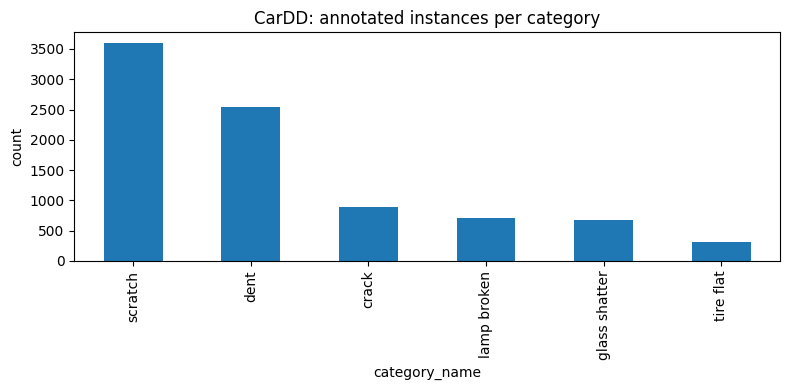

In [4]:
anns_df = pd.DataFrame(all_anns)
anns_df["category_name"] = anns_df["category_id"].map(cat_id_to_name)

# How many annotated instances per category overall?
instance_counts = anns_df["category_name"].value_counts()
print("Instances per category:")
print(instance_counts)

instance_counts.plot(kind="bar", figsize=(8,4), title="CarDD: annotated instances per category")
plt.ylabel("count")
plt.tight_layout()
plt.show()

In [5]:
# How many images have more than one damage instance? This matters for our dominant-label step.
images_per_ann_count = anns_df.groupby(["split", "image_id"]).size()
print(f"Images with exactly 1 annotated instance: {(images_per_ann_count == 1).sum()}")
print(f"Images with more than 1 annotated instance: {(images_per_ann_count > 1).sum()}")

Images with exactly 1 annotated instance: 1816
Images with more than 1 annotated instance: 2184


## Step 5 — Convert to single dominant label per image

CarDD annotates individual damage *instances*, so one image can have several labeled damage regions. For this classification baseline we need exactly one label per image, so we assign each image the category with the **largest total annotated area** — i.e. its most prominent damage.

In [6]:
dominant = (
    anns_df.groupby(["split", "image_id", "category_name"])["area"].sum()
    .reset_index()
    .sort_values("area", ascending=False)
    .drop_duplicates(subset=["split", "image_id"], keep="first")
)

dominant["file_name"] = dominant.apply(
    lambda r: all_images[(r["split"], r["image_id"])]["file_name"], axis=1)
dominant["full_path"] = dominant.apply(
    lambda r: all_images[(r["split"], r["image_id"])]["full_path"], axis=1)

print(f"Total single-labeled images: {len(dominant)}")
print("Class balance after dominant-label conversion:")
print(dominant["category_name"].value_counts())

Total single-labeled images: 4000
Class balance after dominant-label conversion:
category_name
scratch          1324
dent             1173
glass shatter     653
lamp broken       463
tire flat         293
crack              94
Name: count, dtype: int64


## Step 6 — Extract simple features for k-NN

k-NN can't work on raw images directly the way a CNN can, so we resize every image to a small, consistent size and flatten the pixels into a feature vector. This is intentionally simple — the point of Iteration Zero is a quick feasibility check, not a polished pipeline.

In [7]:
IMG_SIZE = (32, 32)  # small on purpose — keeps this fast for a quick baseline

def load_and_flatten(path, size=IMG_SIZE):
    img = Image.open(path).convert("RGB").resize(size)
    return np.asarray(img, dtype=np.float32).flatten() / 255.0

features = []
labels = []
skipped = 0

for _, row in dominant.iterrows():#dominant has one row per photo, labelled with the photo's dominant (biggest) damage. 
                                   #A photo with a dent and a scratch only counts as "dent", and the scratch is thrown away.
    try:
        features.append(load_and_flatten(row["full_path"]))
        labels.append(row["category_name"])
    except (FileNotFoundError, OSError):
        skipped += 1

X = np.stack(features)
y = np.array(labels)
print(f"Feature matrix shape: {X.shape}")
print(f"Skipped (missing/unreadable) images: {skipped}")

Feature matrix shape: (4000, 3072)
Skipped (missing/unreadable) images: 0


## Step 7 — Train / test split

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train size: {len(X_train)}, Test size: {len(X_test)}")

Train size: 3200, Test size: 800


## Step 8 — Train the k-NN baseline (no tuning, default parameters)

In [9]:
#Baseline for comparison: what would pure random guessing score?
n_classes = len(set(y))
random_baseline = 1 / n_classes
print(f"Number of classes: {n_classes}")
print(f"Random-guess baseline: {random_baseline:.1%}")

Number of classes: 6
Random-guess baseline: 16.7%


In [10]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print(f"k-NN baseline accuracy: {acc:.3f}")

k-NN baseline accuracy: 0.394


## Step 9 — Evaluate

Remember: the bar to clear here isn't high accuracy — it's beating random guessing. With 6 classes, random guessing scores roughly **16.7%**. Anything meaningfully above that means the data has a learnable signal worth pursuing with a more capable model (CNN) in later iterations.

               precision    recall  f1-score   support

        crack       0.00      0.00      0.00        19
         dent       0.37      0.36      0.36       234
glass shatter       0.37      0.36      0.36       131
  lamp broken       0.75      0.03      0.06        92
      scratch       0.40      0.63      0.49       265
    tire flat       0.87      0.22      0.35        59

     accuracy                           0.39       800
    macro avg       0.46      0.27      0.27       800
 weighted avg       0.45      0.39      0.36       800



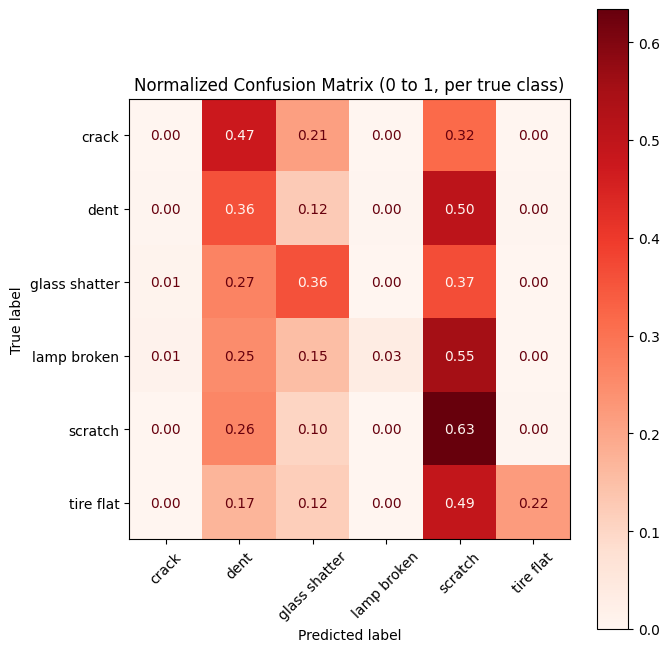

In [11]:
print(classification_report(y_test, y_pred))

# Row-normalized (0 to 1) — each row sums to 1, showing what % of each TRUE class
# was predicted as each label. Fairer than raw counts given class imbalance.
cm_norm = confusion_matrix(y_test, y_pred, labels=knn.classes_, normalize="true")

disp = ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=knn.classes_)
fig, ax = plt.subplots(figsize=(7, 7))
disp.plot(ax=ax, xticks_rotation=45, cmap="Reds", values_format=".2f")
plt.title("Normalized Confusion Matrix (0 to 1, per true class)")
plt.tight_layout()
plt.show()

## Step 10 — Conclusion

**k-NN baseline accuracy:** 39.4% (compared to ~16.7% for random guessing across 6 classes — more than double the random baseline, using a deliberately simple, untuned algorithm on raw flattened pixels).

**Which classes does the model confuse most?** "Scratch" acts as the model's default guess whenever it's unsure — it's the most commonly predicted label across almost every true class, including for images that are actually dents (50% misclassified as scratch), glass shatter (37%), lamp broken (55%), and tire flat (49%). Crack and lamp broken are the most confused classes overall: crack was never predicted correctly at all (0% recall), and lamp broken was correctly identified only 3% of the time.

**Class balance issues found?** Yes — significant imbalance drives the confusion pattern above. Scratch is the largest class (1,324 of 4,000 images), while crack is the smallest (94 images). The two worst-performing classes (crack and lamp broken) are also the two smallest classes in the dataset, and the model's errors consistently fall toward the largest class (scratch) rather than being spread randomly. This points to class imbalance, not the choice of algorithm, as the main limiting factor at this stage.

**Feasibility verdict:** Yes. Despite using a simple, untuned k-NN model on raw pixel data, accuracy is well above the random-guess baseline, showing that the images do contain a learnable visual signal for distinguishing damage types. The project is feasible to continue into later iterations. However, results also show that class imbalance will need to be actively addressed — through data augmentation, class weighting, or oversampling of underrepresented classes (particularly crack and lamp broken) — when developing the CNN model in Iteration 2, rather than assumed away.
